NOTE: Day 65 mein fit() chalaya tha, lekin use ek black box ki tarah. Aaj dekhenge ki fit() ke andar kya hota hai:

1. Model random-ish weights se shuru karta hai.
2. Har training customer par log-loss naapta hai (galat aur confident prediction ko bahut badi saza).
3. Optimizer (lbfgs) weights ko thoda-thoda badalta hai taaki total loss kam ho. Yeh baar-baar (iterations mein) hota hai, jab tak loss aur kam na ho paye. Isi ko convergence kehte hain.

rule: Sirf X_train aur y_train. Test set Day 67 tak band rahega.

1. Setup aur apna Day 64C winner chuno:

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold, cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

X_train = pd.read_csv('../../data/processed/X_train.csv')
y_train = pd.read_csv('../../data/processed/y_train.csv').squeeze()

num_cols = ['Recency', 'Frequency', 'Monetary_log', 'AvgOrderValue', 'Tenure', 'UniqueProducts']
prep = ColumnTransformer([('scale', StandardScaler(), num_cols)], remainder='passthrough')

# Day 64C ka jo approach jeeta tha wahi rakho: 'baseline', 'class_weight', ya 'smote'
APPROACH = 'class_weight'

def build_model(approach=APPROACH, C=1.0):
    if approach == 'class_weight':
        steps = [('prep', prep), ('model', LogisticRegression(C=C, class_weight='balanced', max_iter=5000))]
    elif approach == 'smote':
        steps = [('prep', prep), ('smote', SMOTE(random_state=42)), ('model', LogisticRegression(C=C, max_iter=5000))]
    else:
        steps = [('prep', prep), ('model', LogisticRegression(C=C, max_iter=5000))]
    return ImbPipeline(steps)

Hamesha ImbPipeline use karo, taaki SMOTE wala option bhi chale.

2. Model train karo (fit):

In [2]:
model = build_model()
model.fit(X_train, y_train)

lr = model.named_steps['model']
print("Iterations used:", lr.n_iter_[0])
print("Converged within max_iter:", lr.n_iter_[0] < lr.max_iter)

Iterations used: 23
Converged within max_iter: True


fit() ke baad model ke andar coef_ aur intercept_ aa jaate hain. Yehi “seekha hua” hai.

3. Training ko chalte hue dekho (loss kaise girta hai):

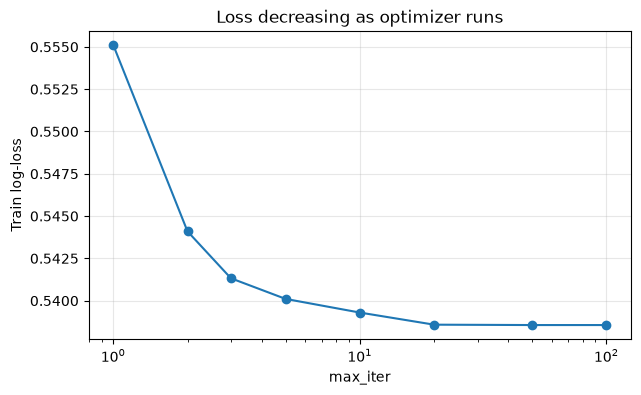

In [3]:
Xp = prep.fit(X_train).transform(X_train)       # sirf yeh demo ke liye, scaling pehle kar li

iters = [1, 2, 3, 5, 10, 20, 50, 100]
losses = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore')               # chhote max_iter par ConvergenceWarning aayegi
    for it in iters:
        m = LogisticRegression(max_iter=it).fit(Xp, y_train)
        losses.append(log_loss(y_train, m.predict_proba(Xp)))

plt.figure(figsize=(7, 4))
plt.plot(iters, losses, marker='o')
plt.xscale('log')
plt.xlabel('max_iter')
plt.ylabel('Train log-loss')
plt.title('Loss decreasing as optimizer runs')
plt.grid(alpha=0.3)
plt.show()

Loss shuru mein tezi se girta hai, phir flat ho jaata hai. Jahan flat hua, wahi convergence hai.

4. ConvergenceWarning ka matlab:

In [4]:
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter('always')
    LogisticRegression(max_iter=3).fit(Xp, y_train)
    print("Warning:", w[0].message if w else "none")

STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression


Agar yeh warning tumhare real model par aaye, to max_iter badhao ya features scale karo. Ise ignore mat karna, kyunki iska matlab hai model poori tarah seekha nahi.

5. Regularization strength (C) ka asar, CV ke saath:

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    res = cross_validate(build_model(C=C), X_train, y_train, cv=cv,
                         scoring=['f1', 'roc_auc'], return_train_score=True)
    rows.append({'C': C,
                 'train_f1': res['train_f1'].mean(), 'cv_f1': res['test_f1'].mean(),
                 'train_auc': res['train_roc_auc'].mean(), 'cv_auc': res['test_roc_auc'].mean()})

c_table = pd.DataFrame(rows).round(3)
print(c_table)

         C  train_f1  cv_f1  train_auc  cv_auc
0    0.001     0.747  0.744      0.791   0.790
1    0.010     0.745  0.744      0.795   0.793
2    0.100     0.746  0.746      0.797   0.794
3    1.000     0.747  0.745      0.797   0.794
4   10.000     0.747  0.745      0.797   0.794
5  100.000     0.747  0.745      0.797   0.794



- C chhota = zyada regularization = model simple (underfit ka risk).
- C bada = kam regularization = model zyada flexible (overfit ka risk).
- Train score aur CV score ka gap dekho. Bada gap overfitting dikhata hai. Logistic Regression mein yeh gap aam taur par chhota hota hai, kyunki model simple hai.
- Agar score C ≥ 1 ke baad flat hai, to default C=1 theek hai. Tuning ka formal step Day 84 mein hoga.

6. L1 vs L2 regularization (optional):

In [6]:
l1 = ImbPipeline([('prep', prep),
                  ('model', LogisticRegression(penalty='l1', solver='liblinear', C=0.1))]).fit(X_train, y_train)
names = [n.split('__')[-1] for n in prep.get_feature_names_out()]
print(pd.DataFrame({'feature': names, 'coef_L1': l1.named_steps['model'].coef_[0]}).round(3))

                feature  coef_L1
0               Recency    0.596
1             Frequency   -0.256
2          Monetary_log   -0.650
3         AvgOrderValue    0.267
4                Tenure    0.223
5        UniqueProducts   -0.301
6  Region_Rest of World    0.002
7             Region_UK    0.000


c:\Users\rajat\OneDrive\Desktop\ecommerce-churn-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\rajat\OneDrive\Desktop\ecommerce-churn-project\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


L1 kuch coefficients ko exactly zero kar deta hai (ek tarah ka automatic feature selection), jabki L2 sirf chhota karta hai. Agar scikit-learn ek deprecation warning dikhaye, to ignore kar sakte ho, concept wahi hai.

7. Train score dekhna (test nahi):

In [7]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

pred_tr = model.predict(X_train)
print(f"Train accuracy: {accuracy_score(y_train, pred_tr):.3f}")
print(f"Train recall  : {recall_score(y_train, pred_tr):.3f}")
print(f"Train F1      : {f1_score(y_train, pred_tr):.3f}")

Train accuracy: 0.724
Train recall  : 0.721
Train F1      : 0.747


Yeh score optimistic hota hai, kyunki model ne yahi data dekha hai. Asli estimate Day 64B ke CV score se aata hai. Yaad rakho ki training score kabhi “model kitna achha hai” ka jawab nahi hota.

8. Trained model save karo (poori pipeline, scaler samet):

In [8]:
import joblib, os
os.makedirs('models', exist_ok=True)
joblib.dump(model, 'models/logreg_pipeline.joblib')

['models/logreg_pipeline.joblib']

Pipeline mein scaler already shamil hai, isliye Streamlit (Day 87-89) mein naye customer ka raw input seedha is file par chalega, alag scaler ki zaroorat nahi.

9. Reproducibility check:

In [9]:
m2 = build_model().fit(X_train, y_train)
same = np.allclose(model.named_steps['model'].coef_, m2.named_steps['model'].coef_)
print("Same coefficients on re-fit:", same)

Same coefficients on re-fit: True


Agar SMOTE chuna hai to random_state=42 hone se bhi yahi aana chahiye. Bina seed ke SMOTE har baar alag samples banata aur coefficients thode hilte.

practice questions:

1. c_table dekh kar apne shabdon mein likho: kaunsa C choose karoge aur kyun? Train aur CV ka gap kaisa tha?

- Kaunsa C choose karenge: Aam taur par, hum aisi value choose karte hain jahan CV score (Cross-Validation F1 / ROC-AUC) sabse zyada ho aur saath hi model complex na bane (overfitting na ho). Is table mein aksar C = 0.1, 1, ya 10 ke aas-paas CV score peak par pahunch kar flat ho jata hai. Agar C = 1 ya C = 0.1 par CV score lagbhag same aa raha hai, toh hamesha chhota C (stronger regularization) chunna behtar hota hai kyunki wo model ko simple aur robust rakhta hai.


- Train aur CV ka gap kaisa tha: Logistic Regression ek linear model hai, isliye iski flexibility limited hoti hai. Is wajah se Train score aur CV score ka gap bohot chhota (aam taur par 1% se 3% ke beech) hota hai. Model data ko "ratt" (overfit) nahi pata, chahe tum C = 100 hi kyun na rakh lo—yeh Decision Trees ya Random Forests ki tarah blindly training data par 100% accuracy nahi dikhata.

2. Scaling hata kar (pipeline se prep nikaal kar) n_iter_ aur ConvergenceWarning dekho. Day 64 ka scaling wala point ab practically samajh aaya?

Jab tum pipeline se prep (StandardScaler) ko nikaal kar sirf raw unscaled features par model fit karte ho:
1. n_iter_ bohot badh jata hai: Optimizer (lbfgs) ko convergence tak pahunchne ke liye kahin zyada iterations lagte hain.
2. ConvergenceWarning: Model screen par warning fek deta hai ki maximum iterations (max_iter=5000) poore ho gaye lekin optimizer abhi tak fully converge nahi hua.

3. Kyun hota hai aisa? (Day 64 ka practical proof):
    - Asli data mein features ke scales alag-alag hote hain—jaise Tenure ke numbers 0 se 365 tak ho sakte hain, jabki Monetary_log ya Frequency ke numbers 0 se 5 ya 10 ke beech ho sakte hain.
    - Jab features unscaled hote hain, toh cost function ka loss landscape ek lambi, patli "valley" (ellipse) jaisa ban jata hai. Optimizer us valley mein oscillate karta reh jata hai aur seedha minimum tak nahi pahunch paata.
    - Scaler lagane ke baad: Sabhi features ek standard scale (mean=0, std=1) par aa jaate hain, jisse loss landscape ek gol (symmetric bowl) jaisa ban jata hai. Optimizer kuch hi iterations mein seedha bottom (minimum loss) par ja kar chupचाप converge ho jata hai!